# 05 · Classic measures, CKS baseline, horizons and the depth law (Day 3: Stages 4–6)
**Microstructure Alpha · Binance USD-M ETHUSDT perpetual · development days only (D1–D5)**

This is the first notebook that relates features to **future prices**. Everything follows the frozen protocol, which is loaded and hash-checked first. Only development days are used; the selection and test days are not opened.

| Section | Content | Hypotheses |
|---|---|---|
| 0 | Post-hoc check of the Stage-0 round-trip explanation (exploratory, not a gate) | — |
| 1 | Classic measures: spread decomposition per taker order, Kyle's λ, trade-sign memory, propagator model, concave size impact | H6 |
| 2 | CKS baseline on 1 s buckets: β, HAC t, R²; OFI vs trade imbalance vs signed order count; β vs 1/(2D̄); decomposition; β by hour; shuffle null | H1 |
| 3 | Horizons 100 ms – 2 min (contemporaneous and walk-forward predictive, permutation null, Romano–Wolf); clock vs event time; depth law; conditioning | H2, H3, H4 |

**Units.** Price changes are in ticks (0.01 USDT; mid at half-tick resolution). OFI and volumes are in ETH. Spreads are in basis points of the mid.

**Conventions.** Newey–West lags = ceil(h / bucket) + 5. Walk-forward is expanding by day within development (train D1 → test D2, …, train D1–4 → test D5). Out-of-sample R² is measured against the zero forecast. The first and last 10 minutes of every day are embargoed in predictive tests.

In [1]:
# ===================== CONFIG =====================
from pathlib import Path
OUT_DIR    = Path(r"C:\microalpha_proj\microoutput")
PERM_REPS  = 1000      # permutation reps for the predictive null (Romano–Wolf); protocol: 1000
BOOT_REPS  = 1000      # block-bootstrap reps (protocol: 1000)
SHUFFLES   = 20        # shuffle-null repetitions for the contemporaneous CKS regression
STRICT     = True
# ==================================================

In [2]:
import sys, time, math, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd()))
import ma_lib
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)
P = ma_lib.load_protocol(OUT_DIR)                       # raises if protocol.json changed after the freeze
REP, TRD, EVT, FEA = OUT_DIR / 'reports', OUT_DIR / 'trades', OUT_DIR / 'events', OUT_DIR / 'features'
DEV = [d for d in P['data_split']['development'] if (FEA / 'ex' / f'feat_ex_{d}.parquet').exists()]
HORIZONS = P['target']['horizons_s']; BIN_S = P['grid']['bin_ms'] / 1000; EMB_MIN = P['purge_embargo']['embargo_minutes']
SEED = P['inference']['seed']; BLOCK_MIN = P['inference']['bootstrap']['block_minutes']
print('protocol OK | stage-0 verdict recorded:', P['stage0']['verdict'])
print('development days available:', DEV, '| horizons (s):', HORIZONS)
if STRICT and len(DEV) != 5: raise RuntimeError('all 5 development days are required')
assert not set(DEV) & set(P['data_split']['test'] + P['data_split']['selection']), 'non-development day in DEV'

GCOLS = ['t_end', 'valid', 'bp1', 'ap1', 'bq1', 'aq1'] + [f'ofi{k}' for k in range(1, 11)] + \
        ['limit_flow', 'market_flow', 'move_flow', 'v_buy', 'v_sell', 'v_buy_x', 'v_sell_x', 'n_buy_orders', 'n_sell_orders', 'mid_changes', 'rv_halfticks2']
def load_grid(date):
    g = pd.read_parquet(FEA / 'ex' / f'feat_ex_{date}.parquet', columns=GCOLS)
    g['ofi_int10'] = g[[f'ofi{k}' for k in range(1, 11)]].sum(axis=1)
    g['ti_x'] = g.v_buy_x - g.v_sell_x
    return g.drop(columns=[f'ofi{k}' for k in range(4, 11)] + ['v_buy_x', 'v_sell_x'])
GRID = {d: load_grid(d) for d in DEV}
print({d: f'{len(g):,} bins, {g.valid.mean():.2%} valid' for d, g in GRID.items()})

protocol OK | stage-0 verdict recorded: NOT PASSED
development days available: ['2026-09-07', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11'] | horizons (s): [0.1, 0.25, 0.5, 1, 5, 30, 120]
{'2026-09-07': '864,000 bins, 99.82% valid', '2026-09-08': '864,000 bins, 99.02% valid', '2026-09-09': '864,000 bins, 99.71% valid', '2026-09-10': '864,000 bins, 97.86% valid', '2026-09-11': '864,000 bins, 99.35% valid'}


## 0 · Post-hoc: are the 'quiet-unexplained' trades round trips inside a batch? (exploratory)
Notebook 04 rejected RPI as the main explanation. The alternative: inside one ~27 ms batch a sweep moves the price 10+ ticks and the book refills, so the mid barely changes between batch boundaries. If so, the trades in those batches should span a **wide price range** and be part of **multi-level sweeps**. This check was designed after seeing notebook 04, so it is reported as exploration, not as a test.

In [3]:
rows = []
for d in DEV:                                          # development days only: selection/test days stay unopened
    f = TRD / f'trades_{d}.parquet'
    if not f.exists(): continue
    t = pd.read_parquet(f, columns=['u_post', 'px', 'cls', 'rpi'])
    t = t[t.u_post >= 0]
    rng_b = t.groupby('u_post').px.agg(lambda s: s.max() - s.min())
    t['batch_range'] = t.u_post.map(rng_b)
    for name, m in (('quiet-unexplained', t.rpi), ('at touch (control)', t.cls == 0)):
        x = t.loc[m, 'batch_range']
        rows.append(dict(date=d, group=name, trades=len(x), median_range_ticks=x.median(), share_range_ge10=(x >= 10).mean()))
rt = pd.DataFrame(rows)
display(rt.pivot(index='date', columns='group', values=['median_range_ticks', 'share_range_ge10']).round(3))

median_range_ticks                     share_range_ge10                  
group      at touch (control) quiet-unexplained at touch (control) quiet-unexplained
date                                                                                
2026-09-07                0.0              13.0              0.265             0.581
2026-09-08                1.0              13.0              0.276             0.760
2026-09-09                1.0              14.0              0.283             0.567
2026-09-10                1.0              10.0              0.273             0.503
2026-09-11                1.0              22.0              0.316             0.827

## 1 · Classic measures (development days)
**Spread decomposition per taker order** (d = +1 buy, p = order VWAP, m = mid before the order's batch, m₊ = mid 5 s later):
effective = 2d(p − m)/m, realized = 2d(p − m₊)/m, **price impact (adverse selection) = effective − realized**, all in bp. The *clean* rows drop orders with any fill that notebook 02 could not place in the book.

In [4]:
t0 = time.time()
ord_rows, signs_by_day, resp_by_day = [], {}, {}
for d in DEV:
    ev = pd.concat([pd.read_parquet(EVT / d / f'events_{d}_{h:02d}.parquet', columns=['u', 'bp1', 'ap1']) for h in range(24)
                    if (EVT / d / f'events_{d}_{h:02d}.parquet').exists()], ignore_index=True)
    o = pd.read_parquet(EVT / f'taker_orders_{d}.parquet')
    o = o[o.usable & (o.u_post >= 0)].sort_values('time', kind='stable').reset_index(drop=True)
    tr = pd.read_parquet(TRD / f'trades_{d}.parquet', columns=['id', 'time', 'sign', 'cls']).sort_values('id', kind='stable')
    new = np.r_[True, (tr.time.to_numpy()[1:] != tr.time.to_numpy()[:-1]) | (tr.sign.to_numpy()[1:] != tr.sign.to_numpy()[:-1])]
    first_id = tr.id.to_numpy()[new]; maxcls = np.maximum.reduceat(tr.cls.to_numpy(), np.nonzero(new)[0])
    o['clean'] = pd.Series(maxcls < 4, index=first_id).reindex(o.oid).to_numpy()
    eu = ev.u.to_numpy(); m2 = (ev.bp1 + ev.ap1).to_numpy(float)
    i = np.clip(np.searchsorted(eu, o.u_post.to_numpy()), 1, len(eu) - 1)
    o['mid_pre'] = m2[i - 1] / 2.0; o['mid_post'] = m2[i] / 2.0
    g = GRID[d]; te = g.t_end.to_numpy(); gm = ((g.bp1 + g.ap1).to_numpy(float)) / 2.0
    j = np.searchsorted(te, o.time.to_numpy() + 5000); okj = j < len(te)
    o['mid_5s'] = np.where(okj, gm[np.minimum(j, len(te) - 1)], np.nan)
    s = o.sign.to_numpy()
    o['eff_bp'] = 2 * s * (o.vwap - o.mid_pre) / o.mid_pre * 1e4
    o['real_bp'] = 2 * s * (o.vwap - o.mid_5s) / o.mid_pre * 1e4
    o['impact_bp'] = o.eff_bp - o.real_bp
    o['imm_impact_ticks'] = s * (o.mid_post - o.mid_pre)
    o['hour'] = pd.to_datetime(o.time, unit='ms').dt.hour; o['date'] = d
    ord_rows.append(o[['date', 'hour', 'time', 'sign', 'qty', 'n_levels', 'emptied_touch', 'clean', 'eff_bp', 'real_bp', 'impact_bp', 'imm_impact_ticks', 'mid_pre']])
    signs_by_day[d] = (s.astype(float), o.mid_pre.to_numpy())
    print(f'{d}: {len(o):,} taker orders ({time.time()-t0:.0f}s)')
OD = pd.concat(ord_rows, ignore_index=True); OD = OD[np.isfinite(OD.real_bp)]
OD['size_decile'] = pd.qcut(OD.qty.rank(method='first'), 10, labels=False) + 1
def sdec(df):
    w = df.qty
    return pd.Series({'orders': len(df), 'eth_median': df.qty.median() / 1000, 'eff_bp': df.eff_bp.mean(), 'real_bp': df.real_bp.mean(),
                      'impact_bp': df.impact_bp.mean(), 'impact_share': df.impact_bp.mean() / df.eff_bp.mean() if df.eff_bp.mean() else np.nan,
                      'eff_bp_vw': np.average(df.eff_bp, weights=w), 'impact_bp_vw': np.average(df.impact_bp, weights=w)})
by_size = OD.groupby('size_decile').apply(sdec, include_groups=False)
by_day = OD.groupby('date').apply(sdec, include_groups=False)
clean = OD[OD.clean].groupby('size_decile').apply(sdec, include_groups=False)
print('by taker-order size decile (all usable orders):'); display(by_size.round(3))
print('robustness: clean orders only (no unplaceable fill):'); display(clean[['orders', 'eff_bp', 'real_bp', 'impact_bp']].round(3))
print('by day:'); display(by_day.round(3))
by_size.to_csv(REP / '05_spread_decomposition_by_size.csv'); by_day.to_csv(REP / '05_spread_decomposition_by_day.csv')

2026-09-07: 566,677 taker orders (2s)
2026-09-08: 637,045 taker orders (5s)
2026-09-09: 722,062 taker orders (8s)
2026-09-10: 756,250 taker orders (12s)
2026-09-11: 1,351,462 taker orders (17s)
by taker-order size decile (all usable orders):


,orders,eth_median,eff_bp,real_bp,impact_bp,impact_share,eff_bp_vw,impact_bp_vw
size_decile,,,,,,,,
1,403340.0,0.009,0.117,-0.084,0.201,1.716,0.119,0.220
2,403340.0,0.018,0.061,-0.185,0.246,4.012,0.052,0.220
3,403339.0,0.039,0.258,-0.413,0.671,2.602,0.261,0.683
4,403340.0,0.090,0.264,-0.472,0.735,2.788,0.262,0.730
5,403339.0,0.200,0.286,-0.462,0.748,2.615,0.287,0.746
6,403340.0,0.400,0.304,-0.546,0.850,2.797,0.303,0.845
7,403339.0,0.808,0.227,-0.373,0.600,2.649,0.215,0.552
8,403340.0,1.562,0.260,-0.562,0.822,3.161,0.254,0.796
9,403339.0,4.120,0.333,-0.781,1.113,3.346,0.343,1.172


robustness: clean orders only (no unplaceable fill):


,orders,eff_bp,real_bp,impact_bp
size_decile,,,,
1,399031.0,0.129,-0.091,0.220
2,393324.0,0.095,-0.224,0.319
3,396378.0,0.275,-0.421,0.697
4,396765.0,0.279,-0.484,0.763
5,396799.0,0.301,-0.484,0.785
6,397258.0,0.318,-0.570,0.888
7,397194.0,0.239,-0.405,0.644
8,395619.0,0.275,-0.599,0.875
9,392106.0,0.359,-0.827,1.187


by day:


,orders,eth_median,eff_bp,real_bp,impact_bp,impact_share,eff_bp_vw,impact_bp_vw
date,,,,,,,,
2026-09-07,566663.0,0.300,0.224,-0.434,0.658,2.940,0.974,2.020
2026-09-08,637039.0,0.304,0.243,-0.467,0.710,2.917,1.236,2.197
2026-09-09,722025.0,0.288,0.244,-0.499,0.743,3.048,0.986,2.056
2026-09-10,756228.0,0.254,0.248,-0.511,0.758,3.063,1.315,2.759
2026-09-11,1351441.0,0.298,0.346,-0.579,0.925,2.674,2.275,3.924


In [5]:
# Kyle's lambda on 1 s buckets: ΔP (ticks) on signed traded volume (ETH)
B1 = {d: ma_lib.bucket_grid(GRID[d], int(round(1 / BIN_S))) for d in DEV}
ky = []
for d in DEV:
    b = B1[d][B1[d].valid]
    r = ma_lib.ols_hac(b.dp_ticks, (b.v_buy - b.v_sell) / 1000, 6)
    ky.append(dict(date=d, lambda_ticks_per_eth=r['beta'][1], t=r['t'][1], r2=r['r2'], n=r['n']))
ky = pd.DataFrame(ky).set_index('date'); print("Kyle's λ (1 s buckets):"); display(ky.round(4))

Kyle's λ (1 s buckets):


,lambda_ticks_per_eth,t,r2,n
date,,,,
2026-09-07,0.0731,10.1942,0.2648,86243
2026-09-08,0.0556,5.1273,0.2410,85555
2026-09-09,0.0730,14.4101,0.2771,86151
2026-09-10,0.0639,12.1625,0.2699,84549
2026-09-11,0.0701,10.9123,0.2663,85841


,orders,acf_lag1,acf_lag100,acf_lag1000,gamma,hurst,R1_ticks,Rmax_ticks,G_beta,G0
date,,,,,,,,,,
2026-09-07,566677,0.2932,0.0473,0.0200,0.3315,0.8343,0.6961,9.0631,0.200,3.8748
2026-09-08,637045,0.3053,0.0522,0.0250,0.3285,0.8358,0.7176,9.0183,0.225,4.9544
2026-09-09,722062,0.2846,0.0514,0.0236,0.2779,0.8610,0.7324,10.7779,0.175,3.9798
2026-09-10,756250,0.3143,0.0566,0.0343,0.2450,0.8775,0.6734,9.3790,0.175,3.9747
2026-09-11,1351462,0.2471,0.0299,0.0148,0.2941,0.8529,0.7746,12.1362,0.125,4.3149


sign-ACF power-law exponent γ = 0.295 [95% CI 0.250, 0.340] across days → Hurst ≈ 0.852
propagator kernel decay β = 0.180 [95% CI 0.134, 0.226]; pooled fit β = 0.175, G0 = 3.9910 ticks
immediate impact ~ size^δ with δ = 0.253 (δ < 1 means concave)
H6: {'long_memory': True, 'transient_impact': True}


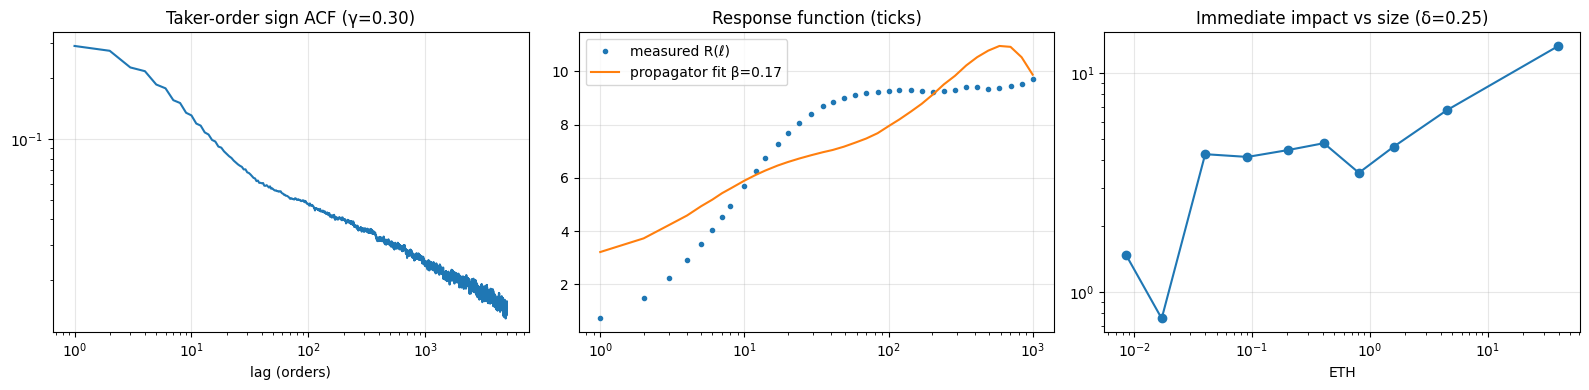

In [6]:
# Trade-sign memory and the propagator (H6), in taker-order time
lags_acf = 5000; lags_R = np.unique(np.round(np.logspace(0, 3, 40)).astype(int))
mem = []; Cs, Rs = [], []
for d, (eps, mid) in signs_by_day.items():
    C = ma_lib.acf_fft(eps, lags_acf); Cs.append(C)
    gam, _ = ma_lib.power_law_fit(np.arange(10, 1001), C[10:1001])
    R = ma_lib.response_function(mid, eps, lags_R); Rs.append(R)
    pf = ma_lib.propagator_fit(C[:2001], lags_R, R, N=2000)
    mem.append(dict(date=d, orders=len(eps), acf_lag1=C[1], acf_lag100=C[100], acf_lag1000=C[1000], gamma=gam, hurst=1 - gam / 2,
                    R1_ticks=R[0], Rmax_ticks=np.nanmax(R), G_beta=pf['beta'], G0=pf['G0']))
mem = pd.DataFrame(mem).set_index('date'); display(mem.round(4))
def tci(x):
    x = np.asarray(x, float); m = x.mean(); h = 2.776 * x.std(ddof=1) / math.sqrt(len(x)) if len(x) > 1 else np.nan   # t(4) for 5 days
    return m, m - h, m + h
g_m, g_lo, g_hi = tci(mem.gamma); b_m, b_lo, b_hi = tci(mem.G_beta)
pooled = ma_lib.propagator_fit(np.mean(Cs, axis=0)[:2001], lags_R, np.nanmean(Rs, axis=0), N=2000)
print(f'sign-ACF power-law exponent γ = {g_m:.3f} [95% CI {g_lo:.3f}, {g_hi:.3f}] across days → Hurst ≈ {1-g_m/2:.3f}')
print(f'propagator kernel decay β = {b_m:.3f} [95% CI {b_lo:.3f}, {b_hi:.3f}]; pooled fit β = {pooled["beta"]:.3f}, G0 = {pooled["G0"]:.4f} ticks')
# concave size impact: immediate impact vs order size
sz = OD.groupby('size_decile').agg(q=('qty', 'mean'), imp=('imm_impact_ticks', 'mean'))
delta, _ = ma_lib.power_law_fit(sz.q, sz.imp); delta = -delta
print(f'immediate impact ~ size^δ with δ = {delta:.3f} (δ < 1 means concave)')
H6 = dict(long_memory=bool(g_hi < 1 and g_lo > 0), transient_impact=bool(b_lo > 0))
print('H6:', H6)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
l = np.arange(1, lags_acf + 1); Cm = np.mean(Cs, axis=0)
ax[0].loglog(l, np.clip(Cm[1:], 1e-5, None)); ax[0].set_title(f'Taker-order sign ACF (γ={g_m:.2f})'); ax[0].set_xlabel('lag (orders)')
ax[1].semilogx(lags_R, np.nanmean(Rs, axis=0), 'o', ms=3, label='measured R(ℓ)'); ax[1].semilogx(lags_R, pooled['pred'], label=f'propagator fit β={pooled["beta"]:.2f}')
ax[1].set_title('Response function (ticks)'); ax[1].legend()
ax[2].loglog(sz.q / 1000, sz.imp, 'o-'); ax[2].set_title(f'Immediate impact vs size (δ={delta:.2f})'); ax[2].set_xlabel('ETH')
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); fig.savefig(REP / '05_memory_propagator.png', dpi=110); plt.show()
mem.to_csv(REP / '05_sign_memory_propagator.csv')

## 2 · CKS baseline (1 s buckets, development days) — H1
ΔP_k = α + β·X_k + ε, per day, with X ∈ {level-1 OFI, trade imbalance (buy − sell volume), signed taker-order count, OFI + TI}. **H1:** β_OFI > 0 with HAC t > 1.96 on every development day, **and** R²(OFI) > R²(TI) on ≥ 4 of 5 days.

In [7]:
res = []
for d in DEV:
    b = B1[d][B1[d].valid]; y = b.dp_ticks.to_numpy()
    X = {'OFI1': b.ofi1 / 1000, 'TI': (b.v_buy - b.v_sell) / 1000, 'signed_orders': b.n_buy_orders - b.n_sell_orders}
    for name, x in X.items():
        r = ma_lib.ols_hac(y, x.to_numpy(), 6); res.append(dict(date=d, model=name, beta=r['beta'][1], t=r['t'][1], r2=r['r2']))
    r = ma_lib.ols_hac(y, np.c_[X['OFI1'], X['TI']], 6); res.append(dict(date=d, model='OFI1+TI', beta=r['beta'][1], t=r['t'][1], r2=r['r2']))
cks = pd.DataFrame(res)
r2t = cks.pivot(index='date', columns='model', values='r2'); display(r2t.round(4))
ofi = cks[cks.model == 'OFI1'].set_index('date')
H1 = dict(beta_positive_every_day=bool(((ofi.beta > 0) & (ofi.t > 1.96)).all()),
          ofi_beats_ti_days=int((r2t.OFI1 > r2t.TI).sum()), supported=bool(((ofi.beta > 0) & (ofi.t > 1.96)).all() and (r2t.OFI1 > r2t.TI).sum() >= 4))
print('β (ticks per ETH of OFI) and HAC t:'); display(ofi[['beta', 't', 'r2']].round(5)); print('H1:', H1)
# magnitude: beta vs 1/(2 D̄)
mag = pd.DataFrame({'beta': ofi.beta, 'Dbar_eth': [B1[d][B1[d].valid].depth_mean.mean() for d in ofi.index],
                    'Dharm_eth': [1 / np.mean(1 / B1[d][B1[d].valid & (B1[d].depth_mean > 0)].depth_mean) for d in ofi.index]})
mag['one_over_2D'] = 1 / (2 * mag.Dbar_eth); mag['ratio_beta_to_1/2D'] = mag.beta / mag.one_over_2D
mag['ratio_beta_to_1/2D_harmonic'] = mag.beta * 2 * mag.Dharm_eth
print('magnitude check: CKS predicts β ≈ c/D with c ≤ 1/2. Mean depth is dominated by occasional large queues, while OFI hits')
print('mostly when the touch is thin, so the harmonic mean depth (≈ 1/E[1/D]) is the fairer normaliser:'); display(mag.round(5))
# decomposition of Cov(OFI, ΔP) into limit / market / move flow
dec = []
for d in DEV:
    b = B1[d][B1[d].valid]; y = b.dp_ticks - b.dp_ticks.mean(); tot = np.mean(y * (b.ofi1 - b.ofi1.mean()))
    dec.append({'date': d, **{c: np.mean(y * (b[c] - b[c].mean())) / tot for c in ('limit_flow', 'market_flow', 'move_flow')}})
dec = pd.DataFrame(dec).set_index('date'); print('share of Cov(OFI1, ΔP) by component (sums to 1):'); display(dec.round(3))
# shuffle null
rng = np.random.default_rng(SEED); sh = []
for d in DEV:
    b = B1[d][B1[d].valid]; y = b.dp_ticks.to_numpy(); x = (b.ofi1 / 1000).to_numpy()
    sh.append(dict(date=d, r2=ma_lib.ols_hac(y, x, 6)['r2'], r2_shuffled_mean=np.mean([ma_lib.ols_hac(y, rng.permutation(x), 0)['r2'] for _ in range(SHUFFLES)])))
sh = pd.DataFrame(sh).set_index('date'); print('shuffle null (must collapse):'); display(sh.round(5))
cks.to_csv(REP / '05_cks_by_day.csv', index=False)

model,OFI1,OFI1+TI,TI,signed_orders
date,,,,
2026-09-07,0.5322,0.6203,0.2648,0.4649
2026-09-08,0.5270,0.6290,0.2410,0.4741
2026-09-09,0.5557,0.6641,0.2771,0.5036
2026-09-10,0.5099,0.6122,0.2699,0.4179
2026-09-11,0.3341,0.4801,0.2663,0.3673


β (ticks per ETH of OFI) and HAC t:


,beta,t,r2
date,,,
2026-09-07,0.03023,96.46581,0.53218
2026-09-08,0.02902,107.88494,0.52705
2026-09-09,0.02678,107.58959,0.55573
2026-09-10,0.02882,71.09270,0.50988
2026-09-11,0.04777,55.99011,0.33405


H1: {'beta_positive_every_day': True, 'ofi_beats_ti_days': 5, 'supported': True}
magnitude check: CKS predicts β ≈ c/D with c ≤ 1/2. Mean depth is dominated by occasional large queues, while OFI hits
mostly when the touch is thin, so the harmonic mean depth (≈ 1/E[1/D]) is the fairer normaliser:


,beta,Dbar_eth,Dharm_eth,one_over_2D,ratio_beta_to_1/2D,ratio_beta_to_1/2D_harmonic
date,,,,,,
2026-09-07,0.03023,128.53044,105.84872,0.00389,7.77217,6.40062
2026-09-08,0.02902,130.40307,110.28263,0.00383,7.56741,6.39980
2026-09-09,0.02678,141.69885,119.77266,0.00353,7.58825,6.41406
2026-09-10,0.02882,138.92770,115.75985,0.00360,8.00710,6.67182
2026-09-11,0.04777,110.36088,81.34847,0.00453,10.54312,7.77147


share of Cov(OFI1, ΔP) by component (sums to 1):


,limit_flow,market_flow,move_flow
date,,,
2026-09-07,-0.038,0.006,1.031
2026-09-08,-0.032,0.004,1.028
2026-09-09,-0.019,0.005,1.014
2026-09-10,-0.014,0.003,1.011
2026-09-11,-0.014,0.006,1.008


shuffle null (must collapse):


,r2,r2_shuffled_mean
date,,
2026-09-07,0.53218,0.00002
2026-09-08,0.52705,0.00001
2026-09-09,0.55573,0.00002
2026-09-10,0.50988,0.00001
2026-09-11,0.33405,0.00001


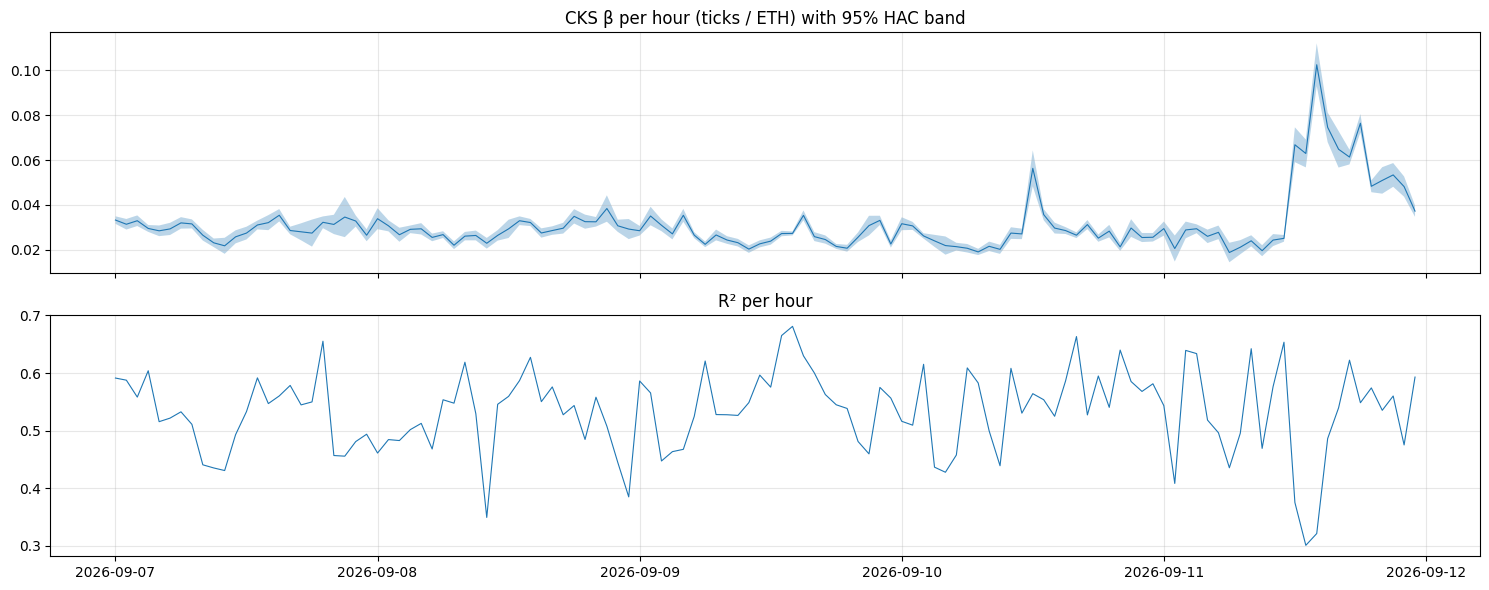

In [8]:
# β per hour with 95% HAC bands (stability)
bh = []
for d in DEV:
    b = B1[d][B1[d].valid].copy(); b['hour'] = pd.to_datetime(b.t_end, unit='ms').dt.hour
    for h, bb in b.groupby('hour'):
        if len(bb) < 300: continue
        r = ma_lib.ols_hac(bb.dp_ticks, bb.ofi1 / 1000, 6)
        bh.append(dict(t=pd.Timestamp(d) + pd.Timedelta(hours=int(h)), beta=r['beta'][1], se=r['se'][1], r2=r['r2'], depth=bb.depth_mean.mean()))
bh = pd.DataFrame(bh)
fig, ax = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
ax[0].plot(bh.t, bh.beta, lw=.8); ax[0].fill_between(bh.t, bh.beta - 1.96 * bh.se, bh.beta + 1.96 * bh.se, alpha=.3); ax[0].set_title('CKS β per hour (ticks / ETH) with 95% HAC band')
ax[1].plot(bh.t, bh.r2, lw=.8); ax[1].set_title('R² per hour')
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); fig.savefig(REP / '05_beta_by_hour.png', dpi=110); plt.show()
bh.to_csv(REP / '05_beta_by_hour.csv', index=False)

## 3 · Horizons (H3), clock vs event time (H4), the depth law (H2), conditioning
**Horizon curve.** For each h: *contemporaneous* ΔP over a bucket of length h on OFI over the same bucket; *predictive* ΔP over the next bucket on OFI over the current one, fit walk-forward. OOS R² is pooled over the test folds. The null permutes the predictor within each test fold. Romano–Wolf adjusts across the horizon grid on statistics **studentized by each horizon's own null**, so long horizons with few samples and a wide null don't drown out the rest. A null that does not collapse would indicate leakage.

h=   0.1s: contemp R² 0.3005 | OOS R² 0.01827 (null 95th pct -0.01291) | n_test 3,373,024
h=  0.25s: contemp R² 0.3343 | OOS R² 0.01418 (null 95th pct -0.01092) | n_test 1,686,510
h=   0.5s: contemp R² 0.3794 | OOS R² 0.01197 (null 95th pct -0.01011) | n_test 674,602
h=     1s: contemp R² 0.4142 | OOS R² 0.00919 (null 95th pct -0.00849) | n_test 337,300
h=     5s: contemp R² 0.4720 | OOS R² 0.00315 (null 95th pct -0.00239) | n_test 67,458
h=    30s: contemp R² 0.4236 | OOS R² 0.00072 (null 95th pct 0.00022) | n_test 11,241
h=   120s: contemp R² 0.2993 | OOS R² -0.00036 (null 95th pct 0.00037) | n_test 2,808


,contemp_r2,oos_r2,null_p95,n_test,beta_last_fold,z_vs_null,rw_p
h_s,,,,,,,
0.10,0.300456,0.018271,-0.012910,3373024,0.006442,256.925310,0.000999
0.25,0.334293,0.014180,-0.010918,1686510,0.005786,169.809012,0.000999
0.50,0.379395,0.011966,-0.010114,674602,0.005213,93.858667,0.000999
1.00,0.414159,0.009190,-0.008493,337300,0.004502,58.810449,0.000999
5.00,0.472011,0.003152,-0.002394,67458,0.002462,15.121837,0.000999
30.00,0.423627,0.000718,0.000217,11241,0.000983,3.090945,0.005994
120.00,0.299325,-0.000365,0.000372,2808,0.000145,0.294687,0.379620


H3: {'any_horizon_significant': True, 'significant_horizons': [0.1, 0.25, 0.5, 1.0, 5.0, 30.0], 'peak_oos_horizon_s': 0.1, 'unrestricted_peak_s': 0.1}


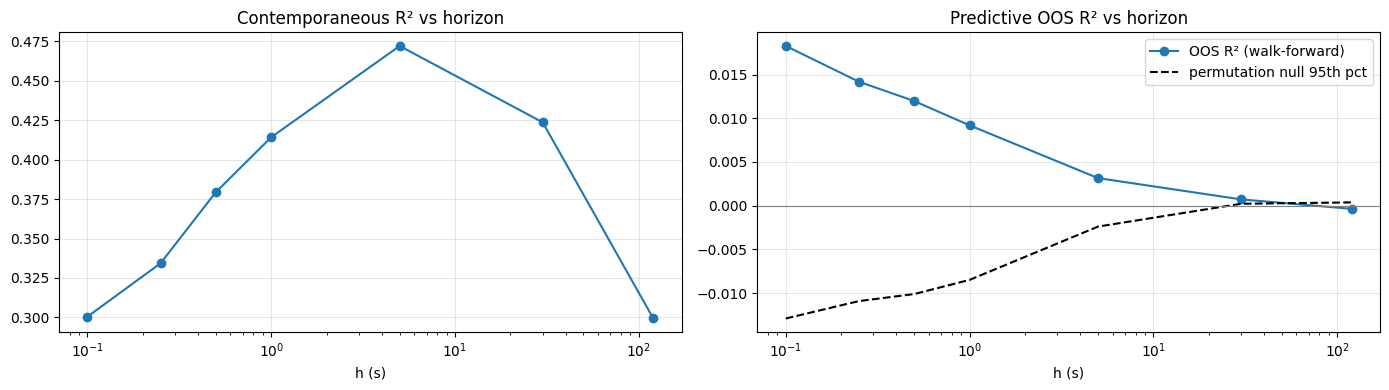

In [9]:
def wf_folds(days): return [(days[:i], days[i]) for i in range(1, len(days))]
def emb_mask(t_end, day):
    t0 = pd.Timestamp(day).value // 10**6; return (t_end >= t0 + EMB_MIN * 60_000) & (t_end <= t0 + 86_400_000 - EMB_MIN * 60_000)
rng = np.random.default_rng(SEED)
hz_rows, null_stats = [], []
for h in HORIZONS:
    k = max(1, int(round(h / BIN_S)))
    data = {}
    for d in DEV:
        b = ma_lib.bucket_grid(GRID[d], k)
        y_next = b.dp_ticks.shift(-1); v_next = b.valid.shift(-1, fill_value=False)
        m = b.valid & v_next & emb_mask(b.t_end, d)
        data[d] = dict(x=(b.ofi1[m] / 1000).to_numpy(), y=y_next[m].to_numpy(), xc=(b.ofi1[b.valid] / 1000).to_numpy(), yc=b.dp_ticks[b.valid].to_numpy())
    xc = np.concatenate([data[d]['xc'] for d in DEV]); yc = np.concatenate([data[d]['yc'] for d in DEV])
    contemp = ma_lib.ols_hac(yc, xc, 0)['r2']
    ys, yh, parts = [], [], []
    for tr_days, te in wf_folds(DEV):
        xtr = np.concatenate([data[d]['x'] for d in tr_days]); ytr = np.concatenate([data[d]['y'] for d in tr_days])
        b0, b1 = ma_lib.ols_hac(ytr, xtr, 0)['beta']
        ys.append(data[te]['y']); yh.append(b0 + b1 * data[te]['x']); parts.append((b0, b1, data[te]['x'], data[te]['y']))
    y_all, yh_all = np.concatenate(ys), np.concatenate(yh)
    r2o = ma_lib.oos_r2(y_all, yh_all) if len(y_all) else np.nan
    # permutation null: only Σ y·x_perm changes, so each rep is one dot product per fold
    SY2 = (y_all ** 2).sum(); nulls = np.zeros(PERM_REPS)
    for rep in range(PERM_REPS):
        sse = 0.0
        for b0, b1, x, y in parts:
            xp = rng.permutation(x); e = y - b0 - b1 * xp; sse += e @ e
        nulls[rep] = 1 - sse / SY2 if SY2 > 0 else np.nan
    null_stats.append(nulls)
    hz_rows.append(dict(h_s=h, contemp_r2=contemp, oos_r2=r2o, null_p95=np.nanpercentile(nulls, 95), n_test=len(y_all),
                        beta_last_fold=parts[-1][1] if parts else np.nan))
    print(f'h={h:>6}s: contemp R² {contemp:.4f} | OOS R² {r2o:.5f} (null 95th pct {np.nanpercentile(nulls, 95):.5f}) | n_test {len(y_all):,}')
hz = pd.DataFrame(hz_rows).set_index('h_s')
NS = np.vstack(null_stats).T                                  # (reps, horizons)
mu, sd = np.nanmean(NS, axis=0), np.nanstd(NS, axis=0)        # studentize per horizon so noisy horizons don't dominate the max
hz['z_vs_null'] = (hz.oos_r2.to_numpy() - mu) / sd
hz['rw_p'] = ma_lib.romano_wolf(hz.z_vs_null.to_numpy(), (NS - mu) / sd) if len(hz) else np.nan
sig = hz[hz.rw_p < 0.05]
H3 = dict(any_horizon_significant=bool(len(sig)), significant_horizons=[float(x) for x in sig.index],
          peak_oos_horizon_s=float(sig.oos_r2.idxmax()) if len(sig) else None,          # peak among horizons that beat the null
          unrestricted_peak_s=float(hz.oos_r2.idxmax()) if hz.oos_r2.notna().any() else None)
display(hz.round(6)); print('H3:', H3)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].semilogx(hz.index, hz.contemp_r2, 'o-'); ax[0].set_title('Contemporaneous R² vs horizon'); ax[0].set_xlabel('h (s)')
ax[1].semilogx(hz.index, hz.oos_r2, 'o-', label='OOS R² (walk-forward)'); ax[1].semilogx(hz.index, hz.null_p95, 'k--', label='permutation null 95th pct')
ax[1].axhline(0, color='grey', lw=.8); ax[1].set_title('Predictive OOS R² vs horizon'); ax[1].legend(); ax[1].set_xlabel('h (s)')
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); fig.savefig(REP / '05_horizon_curve.png', dpi=110); plt.show()
hz.to_csv(REP / '05_horizon_curve.csv')

**Clock vs event time (H4).** The target is the same for every model: ΔP over the next 1 s clock bucket. Only the **feature window** changes:
- **clock**: OFI over the last 1 s
- **mid-change clock**: OFI over the last *k* mid changes
- **volume clock**: OFI over the last *V* ETH traded

*k* and *V* are set on each training fold so that the average window lasts 1 s, which matches the information budget. Because the targets are identical, a Diebold–Mariano test on squared errors is valid. **H4** is supported if **both** event clocks beat the clock window with DM p < 0.05. As a descriptive companion, contemporaneous R² is also shown with *sampling* in event time.

In [10]:
def windows(g, k_mc, vol):
    co = np.cumsum(g.ofi1.to_numpy(float)) / 1000; cm = np.cumsum(g.mid_changes.to_numpy(float)); cv = np.cumsum((g.v_buy + g.v_sell).to_numpy(float)) / 1000
    def by(cum, w):
        s = np.searchsorted(cum, cum - w, side='right') - 1
        return co - np.where(s >= 0, co[np.maximum(s, 0)], 0.0)
    return by(cm, k_mc), by(cv, vol)
k1 = int(round(1 / BIN_S)); dmr = []; oos = {c: ([], []) for c in ('clock', 'midchange', 'volume')}
for tr_days, te in wf_folds(DEV):
    k_mc = max(1.0, np.mean([GRID[d].mid_changes.sum() / (len(GRID[d]) * BIN_S) for d in tr_days]))
    vol = np.mean([(GRID[d].v_buy + GRID[d].v_sell).sum() / 1000 / (len(GRID[d]) * BIN_S) for d in tr_days])
    def frame(d):
        g = GRID[d]; wm, wv = windows(g, k_mc, vol); b = ma_lib.bucket_grid(g, k1)
        end_idx = np.arange(k1 - 1, len(g) // k1 * k1, k1)
        f = pd.DataFrame({'clock': b.ofi1 / 1000, 'midchange': wm[end_idx], 'volume': wv[end_idx], 'y': b.dp_ticks.shift(-1)})
        m = b.valid & b.valid.shift(-1, fill_value=False) & emb_mask(b.t_end, d)
        return f[m]
    TR = pd.concat([frame(d) for d in tr_days]); TE = frame(te)
    for c in oos:
        b0, b1 = ma_lib.ols_hac(TR.y, TR[c], 0)['beta']; oos[c][0].append(TE.y.to_numpy()); oos[c][1].append((b0 + b1 * TE[c]).to_numpy())
    dmr.append(dict(test_day=te, k_midchanges=k_mc, volume_eth=vol))
Y = np.concatenate(oos['clock'][0]); E = {c: (Y - np.concatenate(oos[c][1])) ** 2 for c in oos}
h4 = pd.DataFrame({c: {'oos_r2': ma_lib.oos_r2(Y, np.concatenate(oos[c][1]))} for c in oos}).T
for c in ('midchange', 'volume'):
    stat, p, md_ = ma_lib.dm_test(E['clock'], E[c], 6); h4.loc[c, 'dm_stat_vs_clock'] = stat; h4.loc[c, 'dm_p_event_better'] = p
display(pd.DataFrame(dmr).round(3)); display(h4.round(6))
H4 = dict(midchange_beats_clock=bool(h4.loc['midchange', 'dm_p_event_better'] < 0.05), volume_beats_clock=bool(h4.loc['volume', 'dm_p_event_better'] < 0.05))
H4['supported'] = H4['midchange_beats_clock'] and H4['volume_beats_clock']; print('H4:', H4)
# descriptive: contemporaneous R² when SAMPLING in event time (k mid changes per sample)
desc = []
for d in DEV:
    g = GRID[d]; v = g.valid.to_numpy(); m2 = (g.bp1 + g.ap1).to_numpy(float) / 2
    cm = np.cumsum(g.mid_changes.to_numpy()); co = np.cumsum(g.ofi1.to_numpy(float)) / 1000
    k_mc = max(1, int(round(g.mid_changes.sum() / (len(g) * BIN_S))))
    cut = np.searchsorted(cm, np.arange(k_mc, cm[-1], k_mc)); cut = np.unique(cut[cut < len(g)])
    dp = np.diff(m2[cut]); dx = np.diff(co[cut]); okv = np.minimum.reduceat(v, cut)[1:] if len(cut) > 1 else np.array([])
    r_ev = ma_lib.ols_hac(dp[okv[:len(dp)].astype(bool)], dx[okv[:len(dp)].astype(bool)], 0)['r2'] if len(dp) > 10 else np.nan
    b = B1[d][B1[d].valid]; desc.append(dict(date=d, r2_clock_1s=ma_lib.ols_hac(b.dp_ticks, b.ofi1 / 1000, 0)['r2'], r2_midchange_sampling=r_ev, samples_midchange=len(dp), samples_clock=len(b)))
display(pd.DataFrame(desc).set_index('date').round(4))
h4.to_csv(REP / '05_clock_vs_event.csv')

,test_day,k_midchanges,volume_eth
0,2026-09-08,1.0,29.988
1,2026-09-09,1.0,34.427
2,2026-09-10,1.0,36.850
3,2026-09-11,1.0,37.926


,oos_r2,dm_stat_vs_clock,dm_p_event_better
clock,0.009190,NaN,NaN
midchange,0.009891,1.569305,0.058288
volume,0.006562,-6.171401,1.000000


H4: {'midchange_beats_clock': False, 'volume_beats_clock': False, 'supported': False}


,r2_clock_1s,r2_midchange_sampling,samples_midchange,samples_clock
date,,,,
2026-09-07,0.5322,0.4405,33588,86243
2026-09-08,0.5270,0.4309,40912,85555
2026-09-09,0.5557,0.4542,44686,86151
2026-09-10,0.5099,0.4171,46260,84549
2026-09-11,0.3341,0.2443,79899,85841


**Depth law (H2).** 1 s buckets are split into deciles of **bucket-mean touch depth** D̄, and β is estimated in each decile. The log β vs log D̄ slope gets a 95% CI from a 5-minute block bootstrap. **H2:** the CI excludes 0. Whether it includes −1 (the CKS prediction β ∝ 1/D) is reported. The **open-snapshot** version uses depth at the start of the bucket; errors-in-variables should attenuate it toward 0, and showing both is part of the result.

H2: {'slope_bucket_mean': -0.965, 'ci': [-1.009, -0.914], 'ci_excludes_0': True, 'ci_includes_minus1': True, 'slope_open_snapshot': -0.485, 'ci_open': [-0.532, -0.437], 'supported': True}


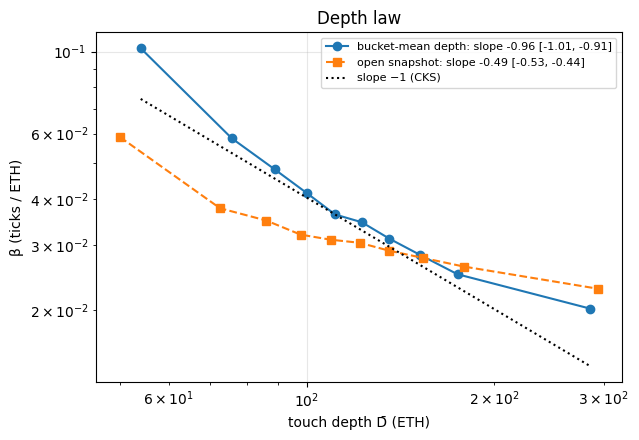

In [11]:
Bd = pd.concat([B1[d][B1[d].valid].assign(date=d) for d in DEV], ignore_index=True)
Bd = Bd[Bd.depth_mean > 0]
def depth_law(df, col, reps):
    dec_ = pd.qcut(df[col].rank(method='first'), 10, labels=False).to_numpy(); x = (df.ofi1 / 1000).to_numpy(); y = df.dp_ticks.to_numpy()
    blk = ma_lib.block_ids(df.t_end.to_numpy(), BLOCK_MIN); ub, inv = np.unique(blk, return_inverse=True)
    S = np.zeros((len(ub), 10, 5))                                     # per block & decile: n, Σx, Σy, Σxx, Σxy
    for j, w in enumerate([np.ones_like(x), x, y, x * x, x * y]):
        np.add.at(S[:, :, j], (inv, dec_), w)
    Dd = np.array([df[col].to_numpy()[dec_ == q].mean() for q in range(10)])
    def slope(Ssum):
        n, sx, sy, sxx, sxy = (Ssum[:, j] for j in range(5))
        beta = (sxy - sx * sy / n) / (sxx - sx * sx / n)
        ok = beta > 0
        return ma_lib.power_law_fit(Dd[ok], beta[ok])[0] * -1 if ok.sum() >= 3 else np.nan, beta
    s0, beta0 = slope(S.sum(axis=0))
    rngb = np.random.default_rng(SEED); boots = np.array([slope(S[rngb.integers(0, len(ub), len(ub))].sum(axis=0))[0] for _ in range(reps)])
    return s0, np.nanpercentile(boots, [2.5, 97.5]), Dd, beta0
s_mean, ci_mean, D_mean, b_mean = depth_law(Bd, 'depth_mean', BOOT_REPS)
s_open, ci_open, D_open, b_open = depth_law(Bd[np.isfinite(Bd.depth_open) & (Bd.depth_open > 0)], 'depth_open', BOOT_REPS)
H2 = dict(slope_bucket_mean=round(float(s_mean), 3), ci=[round(float(c), 3) for c in ci_mean], ci_excludes_0=bool(ci_mean[1] < 0 or ci_mean[0] > 0),
          ci_includes_minus1=bool(ci_mean[0] <= -1 <= ci_mean[1]), slope_open_snapshot=round(float(s_open), 3), ci_open=[round(float(c), 3) for c in ci_open])
H2['supported'] = H2['ci_excludes_0']; print('H2:', H2)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.loglog(D_mean, b_mean, 'o-', label=f'bucket-mean depth: slope {s_mean:.2f} [{ci_mean[0]:.2f}, {ci_mean[1]:.2f}]')
ax.loglog(D_open, b_open, 's--', label=f'open snapshot: slope {s_open:.2f} [{ci_open[0]:.2f}, {ci_open[1]:.2f}]')
ref = b_mean[4] * (D_mean / D_mean[4]) ** -1; ax.loglog(D_mean, ref, 'k:', label='slope −1 (CKS)')
ax.set_xlabel('touch depth D̄ (ETH)'); ax.set_ylabel('β (ticks / ETH)'); ax.legend(fontsize=8); ax.grid(alpha=.3); ax.set_title('Depth law')
plt.tight_layout(); fig.savefig(REP / '05_depth_law.png', dpi=110); plt.show()

In [12]:
# conditioning: β by volatility tercile (hourly realized variance), session and day
Bd['hour'] = pd.to_datetime(Bd.t_end, unit='ms').dt.hour
hv = Bd.groupby(['date', 'hour']).rv_halfticks2.sum(); terc = pd.qcut(hv.rank(method='first'), 3, labels=['low vol', 'mid vol', 'high vol'])
Bd['vol_tercile'] = [terc[(d, h)] for d, h in zip(Bd.date, Bd.hour)]
Bd['session'] = pd.cut(Bd.hour + pd.to_datetime(Bd.t_end, unit='ms').dt.minute / 60, [0, 8, 13.5, 21, 24], right=False, labels=['Asia 00-08', 'Europe 08-13:30', 'US 13:30-21', 'Late 21-24'])
cond = []
for col in ('vol_tercile', 'session', 'date'):
    for k_, bb in Bd.groupby(col, observed=True):
        if len(bb) < 300: continue
        r = ma_lib.ols_hac(bb.dp_ticks, bb.ofi1 / 1000, 6); cond.append(dict(split=col, group=str(k_), beta=r['beta'][1], t=r['t'][1], r2=r['r2'], depth=bb.depth_mean.mean(), n=r['n']))
cond = pd.DataFrame(cond); display(cond.round(5)); cond.to_csv(REP / '05_conditioning.csv', index=False)

,split,group,beta,t,r2,depth,n
0,vol_tercile,high vol,0.03798,112.29631,0.39473,118.32374,140901
1,vol_tercile,low vol,0.02490,105.78489,0.51018,133.94269,143441
2,vol_tercile,mid vol,0.02646,117.60366,0.52959,137.39080,143997
3,session,Asia 00-08,0.02743,110.08803,0.51231,133.85102,143437
4,session,Europe 08-13:30,0.02985,59.58133,0.40725,145.51738,97150
5,session,US 13:30-21,0.03576,117.37872,0.38898,120.81917,133752
6,session,Late 21-24,0.03193,65.66161,0.48755,114.30855,54000
7,date,2026-09-07,0.03023,96.46581,0.53218,128.53044,86243
8,date,2026-09-08,0.02902,107.88494,0.52705,130.40307,85555
9,date,2026-09-09,0.02678,107.58959,0.55573,141.69885,86151


In [13]:
hyp = pd.DataFrame([
    dict(hypothesis='H1', supported=H1['supported'], detail=f"β>0 & t>1.96 every day: {H1['beta_positive_every_day']}; OFI R² > TI R² on {H1['ofi_beats_ti_days']}/{len(DEV)} days"),
    dict(hypothesis='H2', supported=H2['supported'], detail=f"slope {H2['slope_bucket_mean']} CI {H2['ci']} (includes −1: {H2['ci_includes_minus1']}); open-snapshot slope {H2['slope_open_snapshot']} CI {H2['ci_open']}"),
    dict(hypothesis='H3', supported=H3['any_horizon_significant'], detail=f"RW-significant horizons {H3['significant_horizons']}; peak OOS R² among them at {H3['peak_oos_horizon_s']} s (unrestricted peak {H3['unrestricted_peak_s']} s)"),
    dict(hypothesis='H4', supported=H4['supported'], detail=f"mid-change beats clock: {H4['midchange_beats_clock']}; volume beats clock: {H4['volume_beats_clock']}"),
    dict(hypothesis='H6', supported=H6['long_memory'] and H6['transient_impact'], detail=f"γ={g_m:.3f} [{g_lo:.3f},{g_hi:.3f}]; kernel β={b_m:.3f} [{b_lo:.3f},{b_hi:.3f}]; size-impact δ={delta:.3f}")])
display(hyp); hyp.to_csv(REP / '05_hypotheses.csv', index=False)
lines = ['# 05 · Classic measures, CKS, horizons, depth law (development days)', '', f"protocol sha256 verified; development days: {DEV}", '']
lines += [f"{r.hypothesis}: {'SUPPORTED' if r.supported else 'NOT SUPPORTED'} — {r.detail}" for r in hyp.itertuples()]
lines += ['', f"spread decomposition (all orders): effective {OD.eff_bp.mean():.3f} bp, realized(5s) {OD.real_bp.mean():.3f} bp, impact {OD.impact_bp.mean():.3f} bp",
          f"Kyle λ mean {ky.lambda_ticks_per_eth.mean():.5f} ticks/ETH, R² {ky.r2.mean():.4f} vs OFI R² {r2t.OFI1.mean():.4f}",
          f"Cov(OFI,ΔP) shares: limit {dec.limit_flow.mean():.3f}, market {dec.market_flow.mean():.3f}, move {dec.move_flow.mean():.3f}",
          f"β / (1/2D̄) mean ratio {mag['ratio_beta_to_1/2D'].mean():.3f} (arithmetic depth), {mag['ratio_beta_to_1/2D_harmonic'].mean():.3f} (harmonic depth)", f"shuffle-null R² mean {sh.r2_shuffled_mean.mean():.6f} vs real {sh.r2.mean():.4f}"]
(REP / '05_summary.md').write_text('\n'.join(lines), encoding='utf-8'); print('\n'.join(lines))
print('\nSend me: reports/05_summary.md, 05_hypotheses.csv, 05_horizon_curve.csv, 05_clock_vs_event.csv, 05_cks_by_day.csv, '
      '05_spread_decomposition_by_size.csv, 05_sign_memory_propagator.csv, 05_conditioning.csv and the four PNGs')

,hypothesis,supported,detail
0,H1,True,β>0 & t>1.96 every day: True; OFI R² > TI R² o...
1,H2,True,"slope -0.965 CI [-1.009, -0.914] (includes −1:..."
2,H3,True,"RW-significant horizons [0.1, 0.25, 0.5, 1.0, ..."
3,H4,False,mid-change beats clock: False; volume beats cl...
4,H6,True,"γ=0.295 [0.250,0.340]; kernel β=0.180 [0.134,0..."


# 05 · Classic measures, CKS, horizons, depth law (development days)

protocol sha256 verified; development days: ['2026-09-07', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11']

H1: SUPPORTED — β>0 & t>1.96 every day: True; OFI R² > TI R² on 5/5 days
H2: SUPPORTED — slope -0.965 CI [-1.009, -0.914] (includes −1: True); open-snapshot slope -0.485 CI [-0.532, -0.437]
H3: SUPPORTED — RW-significant horizons [0.1, 0.25, 0.5, 1.0, 5.0, 30.0]; peak OOS R² among them at 0.1 s (unrestricted peak 0.1 s)
H4: NOT SUPPORTED — mid-change beats clock: False; volume beats clock: False
H6: SUPPORTED — γ=0.295 [0.250,0.340]; kernel β=0.180 [0.134,0.226]; size-impact δ=0.253

spread decomposition (all orders): effective 0.276 bp, realized(5s) -0.514 bp, impact 0.790 bp
Kyle λ mean 0.06712 ticks/ETH, R² 0.2638 vs OFI R² 0.4918
Cov(OFI,ΔP) shares: limit -0.023, market 0.005, move 1.019
β / (1/2D̄) mean ratio 8.296 (arithmetic depth), 6.732 (harmonic depth)
shuffle-null R² mean 0.000011 vs real 0.4